Imagine This: We’re teachers. We gave a quiz to our class. Some students got questions wrong. We want to help them more next time.

So, we focus more on those students next time. We’re giving them more “weight” — more attention!



In Machine Learning: Each data point has a weight (importance).
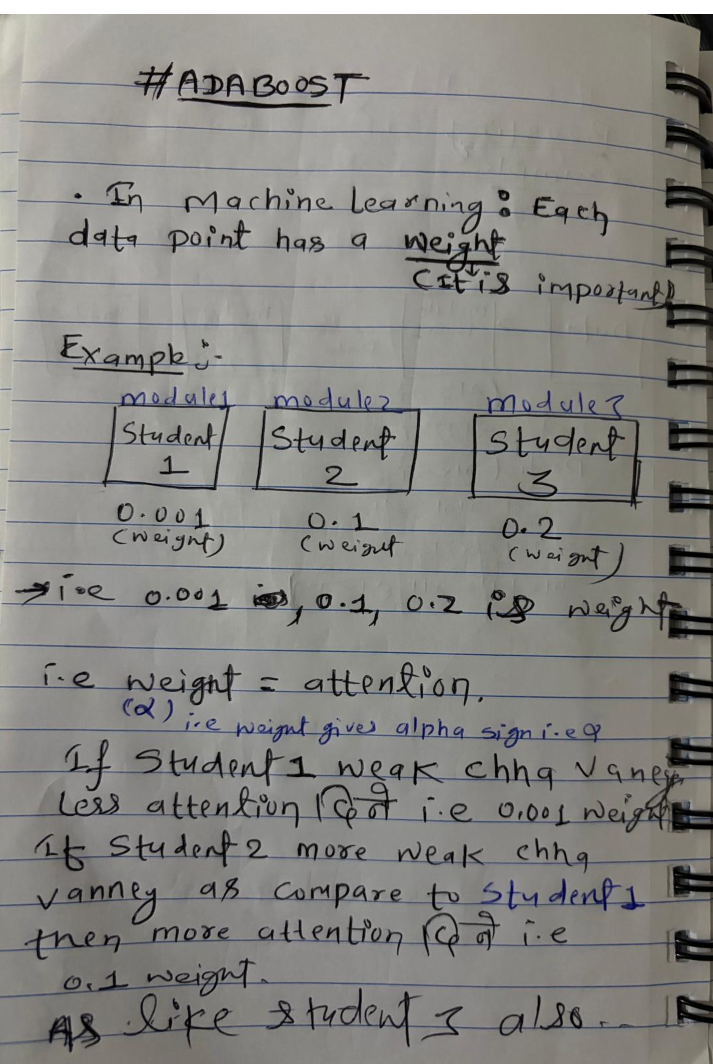

At first, all data points have equal weight (same importance).

After each weak model:

If a point was predicted wrong, increase its weight.

* Tell the next model: “Please try harder on this one.”

If a point was predicted right, lower its weight.

* “This one’s already easy.”
---

# AdaBoost Algorithm
1. Start with equal weights
    * Treat all data points the same at first.
    * Every point is equally important.
2. Train a weak model (stump)
   * Use a tiny decision tree (just one rule) to make predictions.
   * It’s simple and might make mistakes.
3. Check the errors
   * Count how many points it got wrong.
   * Points with higher weights matter more.

4. Give a score to the model
   * If it did well(few mistakes),give it a high score.
   * This score shows how we trust this model.
   

5. Update the weights
   * Increase weight for wrong predictons - so next model focuses on them.
   * Decrease weight for correct ones - they're already easy.
   * Adjust so all weight add up to 1 again.


6. Repeat
     * Train another weak model using the new weights.
     * Do this several times to get better results.

7. Final prediction
    * Combine all models using their scores(weighted vote).
    * The final answer is based on the vote of all the weak models.

# Holiday Package Prediction

# 1) Problem Statement

"Travel.Com" company wants to enable and establish a viable business model to expand the customer base. One of the ways to expand the customer base is to introduce a new offering of packages. Currently, there are 5 types of packages the company is offering - Basic, Standard, Deluxe, Super Deluxe, King. Looking at the data of the last year, we observed that 18% of the customers purchased the packages. However, the marketing cost was quite high because customers were contacted at random without looking at the available information. The company is now planning to launch a new product i.e. Wellness Tourism Package. Wellness Tourism is defined as Travel that allows the traveler to maintain, enhance or kick-start a healthy lifestyle, and support or increase one's sense of well-being.However, this time company wants to harness the available data of existing and potential customers to make the marketing expenditure more efficient.

We need to analyze the customers' data and information to provide recommendations to the Policy Maker and Marketing Team and also build a model to predict the potential customer who is going to purchase the newly introduced travel package.

# 2) Data Collection

* The dataset is collected from:

It consists of 20 columns and 4888 rows.

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('Travel.csv')

In [ ]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


# Data Cleaning
* Handling Missing Values
* Handling Duplicates
* Check Data Type
* Understand the Dataset

# Handling Missing Values

In [ ]:
# Check missing values
df.isnull().sum()

,0
CustomerID,0
ProdTaken,0
Age,226
TypeofContact,25
CityTier,0
DurationOfPitch,251
Occupation,0
Gender,0
NumberOfPersonVisiting,0
NumberOfFollowups,45


# Handling Duplicates

In [ ]:
# Check duplicate rows
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
4883,False
4884,False
4885,False
4886,False


In [ ]:
df.duplicated().sum()

np.int64(0)

# Check Data Types

In [ ]:
# View data types
df.dtypes

,0
CustomerID,int64
ProdTaken,int64
Age,float64
TypeofContact,object
CityTier,int64
DurationOfPitch,float64
Occupation,object
Gender,object
NumberOfPersonVisiting,int64
NumberOfFollowups,float64


In [ ]:
# Check the categories
df['Gender'].value_counts()

,count
Gender,
Male,2916
Female,1817
Fe Male,155


In [ ]:
# Replace duplicates value
df['Gender'] = df['Gender'].replace('Fe Male', 'Female')

In [ ]:
df['Gender'].value_counts()

,count
Gender,
Male,2916
Female,1972


In [ ]:
df['MaritalStatus'].value_counts()

,count
MaritalStatus,
Married,2340
Divorced,950
Single,916
Unmarried,682


In [ ]:
# Replace duplicate value
df['MaritalStatus'] = df['MaritalStatus'].replace('Single', 'Unmarried')

In [ ]:
df['MaritalStatus'].value_counts()

,count
MaritalStatus,
Married,2340
Unmarried,1598
Divorced,950


In [ ]:
df['TypeofContact'].value_counts()

,count
TypeofContact,
Self Enquiry,3444
Company Invited,1419


Checking Missing values

In [ ]:
# These are the features with nan value (Missing Value)
features_with_nan = [features for features in df.columns if df[features].isnull().sum() >= 1]

In [ ]:
features_with_nan

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [ ]:
for feature in features_with_nan:
  print(feature, np.round(df[feature].isnull().mean() * 100, 5), '% missing values')
# np.round(df[feature].isnull().mean() * 100, 5 => feature ma vako data(age..)ko null value lai mean garey raw 100 ley multiply and paxadee 5 ota decimal thapney.

Age 4.62357 % missing values
TypeofContact 0.51146 % missing values
DurationOfPitch 5.13502 % missing values
NumberOfFollowups 0.92062 % missing values
PreferredPropertyStar 0.53191 % missing values
NumberOfTrips 2.86416 % missing values
NumberOfChildrenVisiting 1.35025 % missing values
MonthlyIncome 4.76678 % missing values


# Statistical Summary

In [ ]:
# Statistics on numerical columns(NULL COLS)
df[features_with_nan].select_dtypes(exclude='object').describe()

,Age,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,NumberOfChildrenVisiting,MonthlyIncome
count,4662.000000,4637.000000,4843.000000,4862.000000,4748.000000,4822.000000,4655.000000
mean,37.622265,15.490835,3.708445,3.581037,3.236521,1.187267,23619.853491
std,9.316387,8.519643,1.002509,0.798009,1.849019,0.857861,5380.698361
min,18.000000,5.000000,1.000000,3.000000,1.000000,0.000000,1000.000000
25%,31.000000,9.000000,3.000000,3.000000,2.000000,1.000000,20346.000000
50%,36.000000,13.000000,4.000000,3.000000,3.000000,1.000000,22347.000000
75%,44.000000,20.000000,4.000000,4.000000,4.000000,2.000000,25571.000000
max,61.000000,127.000000,6.000000,5.000000,22.000000,3.000000,98678.000000


 fill in missing value

In [ ]:
# Age
df.Age.fillna(df.Age.median(), inplace=True)

# TypeofContact
df.TypeofContact.fillna(df.TypeofContact.mode()[0], inplace=True)

# DurationnOfPitch
df.DurationOfPitch.fillna(df.DurationOfPitch.median(), inplace=True)

# NumberofFolloups
df.NumberOfFollowups.fillna(df.NumberOfFollowups.mode()[0], inplace=True)

#PreferredProppertyStar
df.PreferredPropertyStar.fillna(df.PreferredPropertyStar.mode()[0], inplace=True)

# NumberOfTrips
df.NumberOfTrips.fillna(df.NumberOfTrips.mode()[0], inplace=True)

# NumberOfChildrenVisiting
df.NumberOfChildrenVisiting.fillna(df.NumberOfChildrenVisiting.mode()[0], inplace=True)

# MonthlyIncome
#df.MonthlyIncome.fillna(df.MonthlyIncome.median()[0], inplace=True)



In [ ]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [ ]:
# Check missing values
df.isnull().sum()

,0
CustomerID,0
ProdTaken,0
Age,0
TypeofContact,0
CityTier,0
DurationOfPitch,0
Occupation,0
Gender,0
NumberOfPersonVisiting,0
NumberOfFollowups,0


In [ ]:
# Remove Customer ID
df.drop('CustomerID', axis=1, inplace=True)

In [ ]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


# Feature Engineering

Feature Extraction

In [ ]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [ ]:
# Create a new column TotalVisits
df['TotalVisits'] = df['NumberOfPersonVisiting'] + df['NumberOfChildrenVisiting']
df.drop(['NumberOfPersonVisiting' , 'NumberOfChildrenVisiting'], axis=1, inplace=True)

In [ ]:
# Get all the numerical columns
numerical_features = [feature for feature in df.columns if df[feature].dtypes != 'object']
print('Number of numerical features:', len(numerical_features))


Number of numerical features: 12


In [ ]:
# Get all the categorical columns
categorical_features = [feature for feature in df.columns if df[feature].dtypes == 'object' ]
print('Number of categorical feature:', len(categorical_features))

Number of categorical feature: 6


In [ ]:
# Discrete features
discrete_features = [feature for feature in numerical_features if len(df[feature].unique()) <=25]
print('Number of categorical features:', len(discrete_features))

Number of categorical features: 9


In [ ]:
# Continuous features
continuous_features = [feature for feature in numerical_features if feature not in discrete_features]
print('Number of continuous features: ', len(continuous_features))

Number of continuous features:  3


In [ ]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisits
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,Manager,20993.0,3.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Unmarried,7.0,1,3,0,Executive,17090.0,3.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0


Train test and model training

In [ ]:
x = df.drop(['ProdTaken'], axis = 1)
y = df['ProdTaken']

In [ ]:
x

,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisits
0,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,Manager,20993.0,3.0
1,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Unmarried,7.0,1,3,0,Executive,17090.0,3.0
3,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4883,49.0,Self Enquiry,3,9.0,Small Business,Male,5.0,Deluxe,4.0,Unmarried,2.0,1,1,1,Manager,26576.0,4.0
4884,28.0,Company Invited,1,31.0,Salaried,Male,5.0,Basic,3.0,Unmarried,3.0,1,3,1,Executive,21212.0,6.0
4885,52.0,Self Enquiry,3,17.0,Salaried,Female,4.0,Standard,4.0,Married,7.0,0,1,1,Senior Manager,31820.0,7.0
4886,19.0,Self Enquiry,3,16.0,Small Business,Male,4.0,Basic,3.0,Unmarried,3.0,0,5,0,Executive,20289.0,5.0


In [ ]:
y

,ProdTaken
0,1
1,0
2,1
3,0
4,0
...,...
4883,1
4884,1
4885,1
4886,1


In [ ]:
y.value_counts()

,count
ProdTaken,
0,3968
1,920


In [ ]:
# Separate the dataset into training and testing set
from sklearn.model_selection import train_test_split
X_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)


In [ ]:
X_train.shape, x_test.shape

((3910, 17), (978, 17))

In [ ]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     4888 non-null   float64
 1   TypeofContact           4888 non-null   object 
 2   CityTier                4888 non-null   int64  
 3   DurationOfPitch         4888 non-null   float64
 4   Occupation              4888 non-null   object 
 5   Gender                  4888 non-null   object 
 6   NumberOfFollowups       4888 non-null   float64
 7   ProductPitched          4888 non-null   object 
 8   PreferredPropertyStar   4888 non-null   float64
 9   MaritalStatus           4888 non-null   object 
 10  NumberOfTrips           4888 non-null   float64
 11  Passport                4888 non-null   int64  
 12  PitchSatisfactionScore  4888 non-null   int64  
 13  OwnCar                  4888 non-null   int64  
 14  Designation             4888 non-null   

In [ ]:
# Create Column Transformer with 3 types of transformers
categorical_features = x.select_dtypes(include='object').columns
numerical_features = x.select_dtypes(exclude='object').columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler() # This is standardScaler object
oh_transformer = OneHotEncoder(drop='first')

preprocessor = ColumnTransformer(
    [
        ('OneHotEncoder', oh_transformer, categorical_features),
        ('StandardScaler', numeric_transformer, numerical_features)
    ]
)

In [ ]:
# Apply Transformation in training set(fit_transform)
x_train = preprocessor.fit_transform(X_train)

In [ ]:
pd.DataFrame(x_train).head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.7214,-1.020350,1.284279,-0.725271,-0.111835,-0.632399,0.679690,0.782966,-0.384685,-0.774151
1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,-0.7214,0.690023,0.282777,-0.725271,1.517765,-0.632399,0.679690,0.782966,-0.460461,0.643615
2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.7214,-1.020350,0.282777,1.771041,0.431365,-0.632399,0.679690,0.782966,-0.250777,-0.065268
3,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,-0.7214,-1.020350,1.284279,-0.725271,-0.111835,-0.632399,1.408395,-1.277194,0.197377,-0.065268
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.7214,2.400396,-1.720227,-0.725271,1.517765,-0.632399,-0.049015,-1.277194,-0.035522,2.061382


In [ ]:
# Apply Tranformtion on test(transform)
x_test = preprocessor.transform(x_test)

In [ ]:
x_test

array([[ 0.        ,  0.        ,  0.        , ..., -1.2771941 ,
        -0.73180503, -0.77415132],
       [ 1.        ,  0.        ,  0.        , ..., -1.2771941 ,
        -0.6662441 , -0.06526803],
       [ 1.        ,  0.        ,  0.        , ...,  0.78296635,
        -0.42238716, -0.77415132],
       ...,
       [ 0.        ,  1.        ,  0.        , ...,  0.78296635,
         0.6629898 ,  0.64361526],
       [ 1.        ,  0.        ,  0.        , ...,  0.78296635,
                nan, -0.77415132],
       [ 1.        ,  1.        ,  0.        , ...,  0.78296635,
        -0.44708859,  2.06138184]])

Machine Learning Model Training


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "AdaBoost": AdaBoostClassifier()
}

for i in range(len(list(models))):
   model = list(models.values())[i]
   model.fit(X_train, y_train) # Train the model


    # Make predictions
   y_train_pred = model.predict(X_train)
   y_test_pred = model.predict(x_test)

    # Training set performance
  model_train_accuracy = accuracy_score(y_train, y_train_pred)  # calculate accuracy
  model_train_f1 = f1_score(y_train, y_train_pred)  # calculate f1 score
  model_train_precision = precision_score(y_train, y_train_pred)  # calculate precision
  model_train_recall = recall_score(y_train, y_train_pred)  # calculate recall
  model_train_roc_auc = roc_auc_score(y_train, y_train_pred)  # calculate roc_auc

    # Test set performance
    model_test_accuracy = accuracy_score(y_test, y_test_pred)  # calculate accuracy
    model_test_f1 = f1_score(y_test, y_test_pred)  # calculate f1 score
    model_test_precision = precision_score(y_test, y_test_pred)  # calculate precision
    model_test_recall = recall_score(y_test, y_test_pred)  # calculate recall
    model_test_roc_auc = roc_auc_score(y_test, y_test_pred)  # calculate roc_auc

    print(f"Model: {list(models.keys())[i]}")

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 18)

In [ ]:
# Initialize few parameters for hyperparameter tuning
ab_params = {
    'n_estimators': [ 50, 100, 150, 200],
    'algorithm': ['SAMME', 'SAMME.R' ],
    'learning_rate': [0.01, 0.1,1,10]
}

In [ ]:
ab_params

{'n_estimators': [50, 100, 150, 200],
 'algorithm': ['SAMME', 'SAMME.R'],
 'learning_rate': [0.01, 0.1, 1, 10]}

In [ ]:
# Models list for hyperparameter tuning
randomcv_models = [
    ('AdaBoost', AdaBoostClassifier(), ab_params)

]

In [ ]:
randomcv_models

[('AdaBoost',
  AdaBoostClassifier(),
  {'n_estimators': [50, 100, 150, 200],
   'algorithm': ['SAMME', 'SAMME.R'],
   'learning_rate': [0.01, 0.1, 1, 10]})]

In [ ]:
# Hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

model_params = {}

for name, model, params in randomcv_models:
  random = RandomizedSearchCV(estimator=model,param_distributions=params,n_iter=100, cv=3,verbose=2,n_jobs=-1)
  random.fit(X_train, y_train)
  model_params[name] = random.best_params_

for model_name in model_params:
  print(f'........Best Parameters for {model_name}.........')
  print(model_params[model_name])

In [ ]:
## Retrain the models with best parameters
models = {

    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=1, algorithm='SAMME.R'),
}

for i in range(len(list(models))):
  model = list(models.values())[i]
  model.fit(X_train, y_train) # Train the model


    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(x_test)

    # Training set performance
    model_train_accuracy = accuracy_score(y_train, y_train_pred)  # calculate accuracy
    model_train_f1 = f1_score(y_train, y_train_pred)  # calculate f1 score
    model_train_precision = precision_score(y_train, y_train_pred)  # calculate precision
    model_train_recall = recall_score(y_train, y_train_pred)  # calculate recall
    model_train_roc_auc = roc_auc_score(y_train, y_train_pred)  # calculate roc_auc

    # Test set performance
    model_test_accuracy = accuracy_score(y_test, y_test_pred)  # calculate accuracy
    model_test_f1 = f1_score(y_test, y_test_pred)  # calculate f1 score
    model_test_precision = precision_score(y_test, y_test_pred)  # calculate precision
    model_test_recall = recall_score(y_test, y_test_pred)  # calculate recall
    model_test_roc_auc = roc_auc_score(y_test, y_test_pred)  # calculate roc_auc

    print(f"Model: {list(models.keys())[i]}")

IndentationError: unexpected indent (609452678.py, line 13)